# Ejercicio 11. La mochila entera, el tamaño de la entrada y la primalidad

Este cuaderno acompaña al informe [`ejercicio-11.md`](ejercicio-11.md). Ejecuta
el mismo código, comprueba la tabla de programación dinámica contra fuerza bruta,
cuenta exactamente sus operaciones, mide el tamaño de la entrada en bits y genera
`ejercicio-11.png`. Las secciones siguen la numeración del informe.

Las cuentas son de operaciones del modelo RAM de la conferencia 1, no de segundos.
Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.

In [1]:
from itertools import product
from random import Random

import matplotlib.pyplot as plt
from IPython.display import Image, display

## 1. Formulación y modelo

Pesos enteros $w_i\ge1$, valores enteros $v_i\ge0$ y capacidad entera $W\ge0$.
Cada objeto se usa a lo sumo una vez. El contador `ops` cuenta las actualizaciones
de la tabla (una comparación y, a lo sumo, una escritura), sin su inicialización.
`input_bits` suma los bits de los $2n+1$ números de la entrada; el cero ocupa un bit.

In [2]:
def knapsack(weights, values, capacity):
    """Valor máximo de un subconjunto de peso total <= capacity.
    Devuelve (valor, ops): ops cuenta las actualizaciones de la tabla."""
    if len(weights) != len(values):
        raise ValueError("pesos y valores deben tener el mismo largo")
    if capacity < 0 or any(w < 1 for w in weights) or any(v < 0 for v in values):
        raise ValueError("se requieren pesos >= 1, valores >= 0 y capacidad >= 0")
    best = [0] * (capacity + 1)  # best[c]: valor máximo con capacidad c
    ops = 0
    for w, v in zip(weights, values):
        for c in range(capacity, w - 1, -1):  # de mayor a menor: cada objeto, una vez
            ops += 1
            if best[c - w] + v > best[c]:
                best[c] = best[c - w] + v
    return best[capacity], ops


def bits(x):
    return max(x, 1).bit_length()


def input_bits(weights, values, capacity):
    return sum(bits(w) + bits(v) for w, v in zip(weights, values)) + bits(capacity)


def knapsack_brute(weights, values, capacity):
    best = 0
    for chosen in product([0, 1], repeat=len(weights)):
        if sum(w for w, x in zip(weights, chosen) if x) <= capacity:
            best = max(best, sum(v for v, x in zip(values, chosen) if x))
    return best


def exact_ops(weights, capacity):
    return sum(max(0, capacity - w + 1) for w in weights)

La tabla se compara con fuerza bruta en instancias aleatorias, y se comprueba
que el contador coincide con $\sum_i\max(0,W-w_i+1)$ y no supera $nW$.

In [3]:
rng = Random(11)
cases = 0
for _ in range(500):
    n = rng.randint(0, 8)
    weights = [rng.randint(1, 9) for _ in range(n)]
    values = [rng.randint(0, 20) for _ in range(n)]
    capacity = rng.randint(0, 30)
    value, ops = knapsack(weights, values, capacity)
    assert value == knapsack_brute(weights, values, capacity)
    assert ops == exact_ops(weights, capacity) <= n * capacity
    cases += 1

assert knapsack([5], [7], 4) == (0, 0)  # un objeto que no cabe no cuesta nada
assert knapsack([2, 3], [3, 4], 0) == (0, 0)
for bad in [([0], [1], 3), ([1], [-1], 3), ([1], [1], -1), ([1, 2], [1], 3)]:
    try:
        knapsack(*bad)
        raise AssertionError("debía fallar")
    except ValueError:
        pass
print(f"ok: {cases} instancias aleatorias contra fuerza bruta, con el contador exacto")

ok: 500 instancias aleatorias contra fuerza bruta, con el contador exacto


## 2. No es polinomial en el tamaño de la entrada

Familia A: dos objetos de peso 1 y valor 1, y $W=2^k$. Familia B: dos objetos de
peso $2^{k-1}$ y valor 1, con $W=2^k$; aquí $W=\sum_i w_i$, así que recortar $W$
a la suma de los pesos no ayuda. Se ejecuta el algoritmo y se compara el contador
con las fórmulas del informe: $L=k+5$ y $\mathrm{ops}=2^{L-4}$ en A,
$L=3k+3$ y $\mathrm{ops}=2^k+2$ en B.

In [4]:
print(f"{'k':>3} {'L (A)':>6} {'ops (A)':>9} {'2^(L-4)':>9} {'L (B)':>6} {'ops (B)':>9}")
family = []
for k in range(4, 19):
    W = 2 ** k
    a = ([1, 1], [1, 1], W)
    b = ([W // 2, W // 2], [1, 1], W)
    value_a, ops_a = knapsack(*a)
    value_b, ops_b = knapsack(*b)
    L_a, L_b = input_bits(*a), input_bits(*b)
    assert value_a == 2 and value_b == 2
    assert L_a == k + 5 and ops_a == 2 ** (L_a - 4)
    assert L_b == 3 * k + 3 and ops_b == 2 ** k + 2
    family.append((k, L_a, ops_a, L_b, ops_b))
    print(f"{k:>3} {L_a:>6} {ops_a:>9,} {2 ** (L_a - 4):>9,} {L_b:>6} {ops_b:>9,}")
print("ok: en A cada bit más de entrada duplica las operaciones")

  k  L (A)   ops (A)   2^(L-4)  L (B)   ops (B)
  4      9        32        32     15        18
  5     10        64        64     18        34
  6     11       128       128     21        66
  7     12       256       256     24       130
  8     13       512       512     27       258
  9     14     1,024     1,024     30       514
 10     15     2,048     2,048     33     1,026
 11     16     4,096     4,096     36     2,050
 12     17     8,192     8,192     39     4,098
 13     18    16,384    16,384     42     8,194
 14     19    32,768    32,768     45    16,386
 15     20    65,536    65,536     48    32,770
 16     21   131,072   131,072     51    65,538
 17     22   262,144   262,144     54   131,074
 18     23   524,288   524,288     57   262,146
ok: en A cada bit más de entrada duplica las operaciones


## 3. Sí es polinomial en $n$ y en el valor de $W$

Con objetos de peso 1 las actualizaciones son exactamente $nW$. Con $n$ fijo la
dependencia en $W$ es lineal, y con $W$ fijo, lineal en $n$.

In [5]:
scaling = {}
print(f"{'n':>4}" + "".join(f"{'W=2^' + str(e):>10}" for e in range(8, 15, 2)))
for n in [1, 4, 16]:
    row = []
    for e in range(8, 15, 2):
        W = 2 ** e
        _, ops = knapsack([1] * n, [1] * n, W)
        assert ops == n * W
        row.append((W, ops))
    scaling[n] = row
    print(f"{n:>4}" + "".join(f"{ops:>10,}" for _, ops in row))
print("ok: ops = n * W en todas las celdas")

   n     W=2^8    W=2^10    W=2^12    W=2^14
   1       256     1,024     4,096    16,384
   4     1,024     4,096    16,384    65,536
  16     4,096    16,384    65,536   262,144
ok: ops = n * W en todas las celdas


## 4. Comparación con la primalidad por división

Se repite el cálculo de la sección 8 de la conferencia 1 a $10^9$ operaciones por
segundo. Para $b$ bits en $W$, con $n=2$ objetos de peso 1, el algoritmo hace
$2\cdot2^{b-1}=2^b$ actualizaciones; la división de prueba hace $2^{b/2}$ divisiones.

In [6]:
SECONDS_PER_YEAR = 3600 * 24 * 365


def human(seconds):
    if seconds < 60:
        return f"{seconds:.3g} segundos"
    return f"{seconds / SECONDS_PER_YEAR:.3g} años"


print(f"{'bits':>5} {'mochila (n=2)':>14} {'tiempo':>16} {'división':>11} {'tiempo':>16}")
for b in [32, 64, 128]:
    knap = 2 ** b
    trial = 2 ** (b // 2)
    print(f"{b:>5} {float(knap):>14.3g} {human(knap / 1e9):>16} "
          f"{float(trial):>11.3g} {human(trial / 1e9):>16}")
assert exact_ops([1, 1], 2 ** 31) == 2 ** 32

 bits  mochila (n=2)           tiempo    división           tiempo
   32       4.29e+09    4.29 segundos    6.55e+04 6.55e-05 segundos
   64       1.84e+19         585 años    4.29e+09    4.29 segundos
  128        3.4e+38    1.08e+22 años    1.84e+19         585 años


## 5. Figura 1

A la izquierda, las operaciones frente al tamaño de la entrada en bits: la familia A
medida, las divisiones de prueba $2^{b/2}$ y una referencia polinomial $L^3$.
A la derecha, las operaciones frente al valor de $W$ para $n=1,4,16$, en ejes
logarítmicos: pendiente 1.

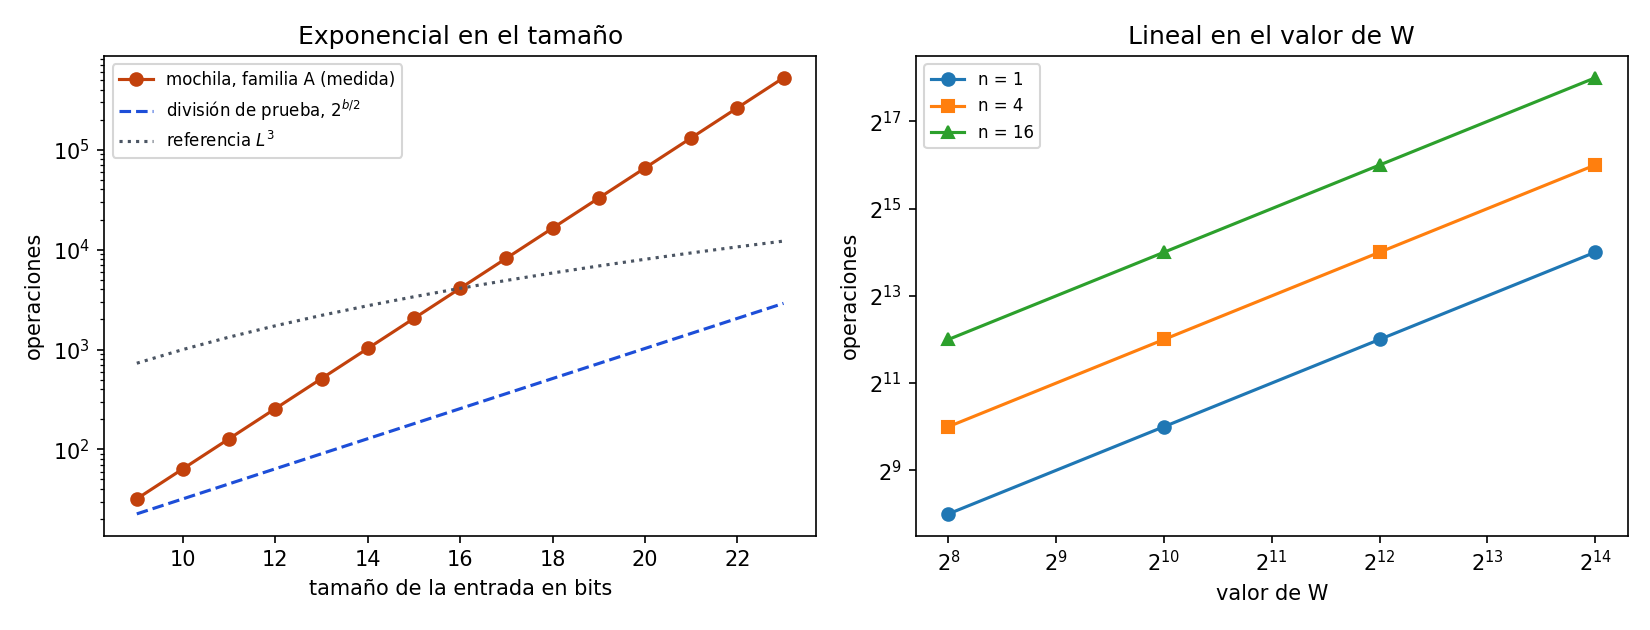

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))

ls = [row[1] for row in family]
left.plot(ls, [row[2] for row in family], "o-", color="#c2410c",
          label="mochila, familia A (medida)")
left.plot(ls, [2 ** (l / 2) for l in ls], "--", color="#1d4ed8",
          label="división de prueba, $2^{b/2}$")
left.plot(ls, [l ** 3 for l in ls], ":", color="#4b5563", label="referencia $L^3$")
left.set_yscale("log")
left.set_xlabel("tamaño de la entrada en bits")
left.set_ylabel("operaciones")
left.set_title("Exponencial en el tamaño")
left.legend(fontsize=8)

for n, marker in zip(scaling, ["o", "s", "^"]):
    right.plot([w for w, _ in scaling[n]], [ops for _, ops in scaling[n]],
               marker + "-", label=f"n = {n}")
right.set_xscale("log", base=2)
right.set_yscale("log", base=2)
right.set_xlabel("valor de W")
right.set_ylabel("operaciones")
right.set_title("Lineal en el valor de W")
right.legend(fontsize=8)

fig.tight_layout()
fig.savefig("ejercicio-11.png", dpi=150)
plt.close(fig)
display(Image("ejercicio-11.png"))